In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("historical_sales_data.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,Date,Sales,Orders,Customers,AverageOrderValue
0,2022-01-01,87484,209,175,418.58
1,2022-02-01,90987,200,162,454.94
2,2022-03-01,100360,251,195,399.84
3,2022-04-01,107819,219,181,492.32
4,2022-05-01,99239,254,206,390.70


In [4]:
df.shape

(48, 5)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Date               48 non-null     str    
 1   Sales              48 non-null     int64  
 2   Orders             48 non-null     int64  
 3   Customers          48 non-null     int64  
 4   AverageOrderValue  48 non-null     float64
dtypes: float64(1), int64(3), str(1)
memory usage: 2.0 KB


In [6]:
df.describe()

,Sales,Orders,Customers,AverageOrderValue
count,48.000000,48.000000,48.000000,48.000000
mean,118640.020833,269.875000,203.187500,443.156667
std,21132.333473,53.507059,43.263987,40.599326
min,84496.000000,181.000000,129.000000,380.610000
25%,101160.500000,227.750000,174.750000,407.002500
50%,117716.500000,259.500000,195.000000,443.055000
75%,134632.250000,309.500000,237.250000,481.330000
max,163291.000000,375.000000,298.000000,517.770000


In [7]:
df.isnull().sum()

Date                 0
Sales                0
Orders               0
Customers            0
AverageOrderValue    0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["Date"] = pd.to_datetime(df["Date"])

print("Date column converted successfully!")

Date column converted successfully!


In [10]:
df = df.sort_values("Date")

print("Data sorted by date!")

Data sorted by date!


In [11]:
df.dtypes

Date                 datetime64[us]
Sales                         int64
Orders                        int64
Customers                     int64
AverageOrderValue           float64
dtype: object

In [12]:
print("Start Date:", df["Date"].min())
print("End Date:", df["Date"].max())

Start Date: 2022-01-01 00:00:00
End Date: 2025-12-01 00:00:00


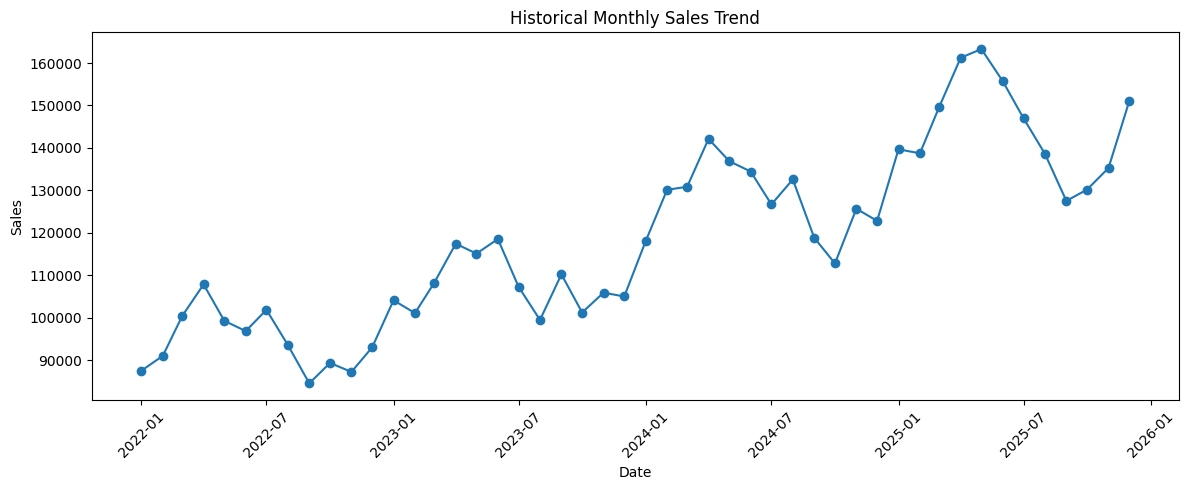

In [13]:
plt.figure(figsize=(12, 5))

plt.plot(df["Date"], df["Sales"], marker="o")

plt.title("Historical Monthly Sales Trend")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [14]:
df["Month"] = df["Date"].dt.month
df["MonthName"] = df["Date"].dt.month_name()

df.head()

,Date,Sales,Orders,Customers,AverageOrderValue,Month,MonthName
0,2022-01-01,87484,209,175,418.58,1,January
1,2022-02-01,90987,200,162,454.94,2,February
2,2022-03-01,100360,251,195,399.84,3,March
3,2022-04-01,107819,219,181,492.32,4,April
4,2022-05-01,99239,254,206,390.70,5,May


In [15]:
monthly_sales = df.groupby(
    ["Month", "MonthName"]
)["Sales"].mean().reset_index()

monthly_sales

,Month,MonthName,Sales
0,1,January,112312.50
1,2,February,115220.25
2,3,March,122270.75
3,4,April,132146.50
4,5,May,128618.00
5,6,June,126360.75
6,7,July,120686.75
7,8,August,116032.50
8,9,September,110246.00
9,10,October,108361.75


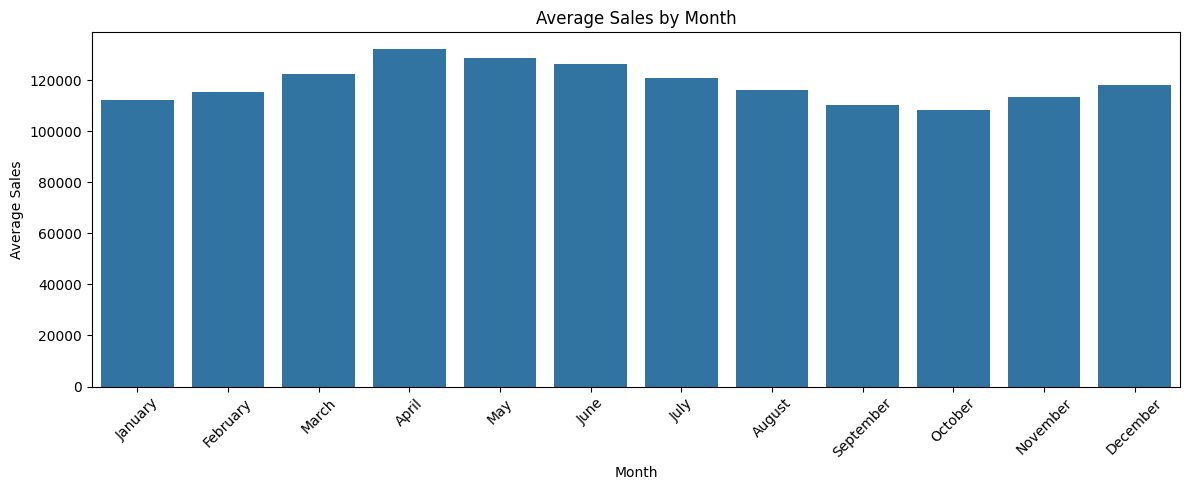

In [16]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=monthly_sales,
    x="MonthName",
    y="Sales"
)

plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Sales")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [17]:
model_data = df[["Date", "Sales"]].copy()

model_data.head()

,Date,Sales
0,2022-01-01,87484
1,2022-02-01,90987
2,2022-03-01,100360
3,2022-04-01,107819
4,2022-05-01,99239


In [18]:
model_data["Time"] = np.arange(len(model_data))

model_data.head()

,Date,Sales,Time
0,2022-01-01,87484,0
1,2022-02-01,90987,1
2,2022-03-01,100360,2
3,2022-04-01,107819,3
4,2022-05-01,99239,4


In [19]:
from sklearn.linear_model import LinearRegression

print("Linear Regression imported successfully!")

Linear Regression imported successfully!


In [20]:
X = model_data[["Time"]]
y = model_data["Sales"]

train_size = int(len(model_data) * 0.8)

X_train = X.iloc[:train_size]
X_test = X.iloc[train_size:]

y_train = y.iloc[:train_size]
y_test = y.iloc[train_size:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 38
Testing records: 10


In [21]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [22]:
y_pred = model.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [23]:
comparison = pd.DataFrame({
    "Date": model_data["Date"].iloc[train_size:],
    "Actual_Sales": y_test.values,
    "Predicted_Sales": np.round(y_pred, 2)
})

comparison

,Date,Actual_Sales,Predicted_Sales
38,2025-03-01,149670,135300.69
39,2025-04-01,161240,136523.46
40,2025-05-01,163291,137746.24
41,2025-06-01,155685,138969.01
42,2025-07-01,146975,140191.79
43,2025-08-01,138594,141414.56
44,2025-09-01,127496,142637.34
45,2025-10-01,130180,143860.11
46,2025-11-01,135254,145082.89
47,2025-12-01,150986,146305.66


In [30]:
model_data["Month"] = model_data["Date"].dt.month

model_data["Month_sin"] = np.sin(
    2 * np.pi * model_data["Month"] / 12
)

model_data["Month_cos"] = np.cos(
    2 * np.pi * model_data["Month"] / 12
)

model_data.head()

,Date,Sales,Time,Month,Month_sin,Month_cos
0,2022-01-01,87484,0,1,0.500000,8.660254e-01
1,2022-02-01,90987,1,2,0.866025,5.000000e-01
2,2022-03-01,100360,2,3,1.000000,6.123234e-17
3,2022-04-01,107819,3,4,0.866025,-5.000000e-01
4,2022-05-01,99239,4,5,0.500000,-8.660254e-01


In [31]:
X = model_data[["Time", "Month_sin", "Month_cos"]]
y = model_data["Sales"]

In [32]:
train_size = int(len(model_data) * 0.8)

X_train = X.iloc[:train_size]
X_test = X.iloc[train_size:]

y_train = y.iloc[:train_size]
y_test = y.iloc[train_size:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 38
Testing records: 10


In [33]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [34]:
y_pred = model.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [35]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 4))

Model Evaluation Results
------------------------
MAE : 5658.48
RMSE: 6592.32
R²  : 0.6955


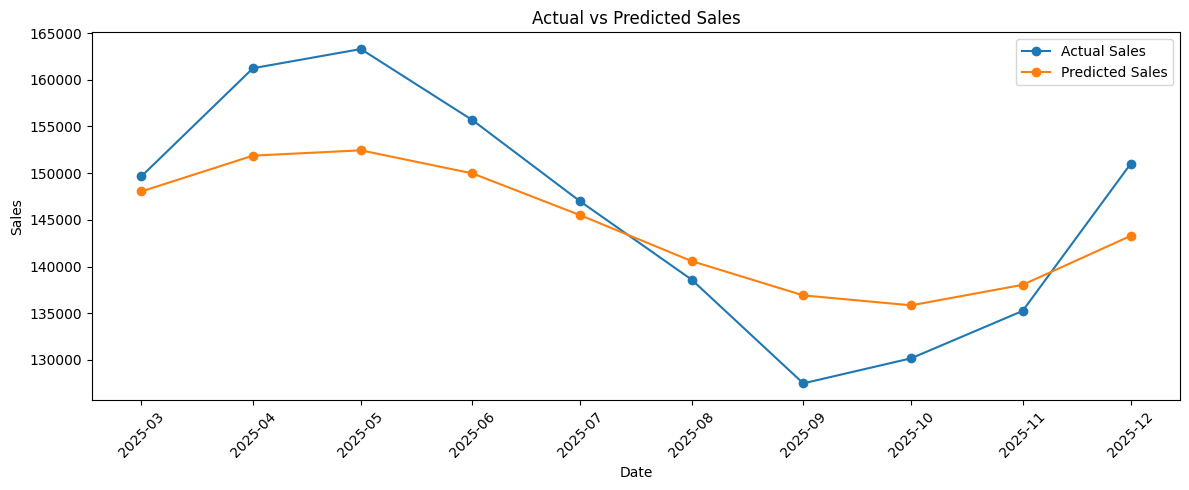

In [36]:
plt.figure(figsize=(12, 5))

plt.plot(
    model_data["Date"].iloc[train_size:],
    y_test,
    marker="o",
    label="Actual Sales"
)

plt.plot(
    model_data["Date"].iloc[train_size:],
    y_pred,
    marker="o",
    label="Predicted Sales"
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.show()

In [37]:
future_dates = pd.date_range(
    start="2026-01-01",
    periods=12,
    freq="MS"
)

future_data = pd.DataFrame({
    "Date": future_dates
})

future_data

,Date
0,2026-01-01
1,2026-02-01
2,2026-03-01
3,2026-04-01
4,2026-05-01
5,2026-06-01
6,2026-07-01
7,2026-08-01
8,2026-09-01
9,2026-10-01


In [38]:
future_data["Time"] = np.arange(
    len(model_data),
    len(model_data) + 12
)

future_data["Month"] = future_data["Date"].dt.month

future_data["Month_sin"] = np.sin(
    2 * np.pi * future_data["Month"] / 12
)

future_data["Month_cos"] = np.cos(
    2 * np.pi * future_data["Month"] / 12
)

future_data

,Date,Time,Month,Month_sin,Month_cos
0,2026-01-01,48,1,5.000000e-01,8.660254e-01
1,2026-02-01,49,2,8.660254e-01,5.000000e-01
2,2026-03-01,50,3,1.000000e+00,6.123234e-17
3,2026-04-01,51,4,8.660254e-01,-5.000000e-01
4,2026-05-01,52,5,5.000000e-01,-8.660254e-01
5,2026-06-01,53,6,1.224647e-16,-1.000000e+00
6,2026-07-01,54,7,-5.000000e-01,-8.660254e-01
7,2026-08-01,55,8,-8.660254e-01,-5.000000e-01
8,2026-09-01,56,9,-1.000000e+00,-1.836970e-16
9,2026-10-01,57,10,-8.660254e-01,5.000000e-01


In [39]:
future_X = future_data[
    ["Time", "Month_sin", "Month_cos"]
]

future_data["Predicted_Sales"] = np.round(
    model.predict(future_X),
    2
)

future_data

,Date,Time,Month,Month_sin,Month_cos,Predicted_Sales
0,2026-01-01,48,1,5.000000e-01,8.660254e-01,150526.37
1,2026-02-01,49,2,8.660254e-01,5.000000e-01,158207.95
2,2026-03-01,50,3,1.000000e+00,6.123234e-17,164639.42
3,2026-04-01,51,4,8.660254e-01,-5.000000e-01,168467.90
4,2026-05-01,52,5,5.000000e-01,-8.660254e-01,169037.99
5,2026-06-01,53,6,1.224647e-16,-1.000000e+00,166567.36
6,2026-07-01,54,7,-5.000000e-01,-8.660254e-01,162088.46
7,2026-08-01,55,8,-8.660254e-01,-5.000000e-01,157171.84
8,2026-09-01,56,9,-1.000000e+00,-1.836970e-16,153505.33
9,2026-10-01,57,10,-8.660254e-01,5.000000e-01,152441.81


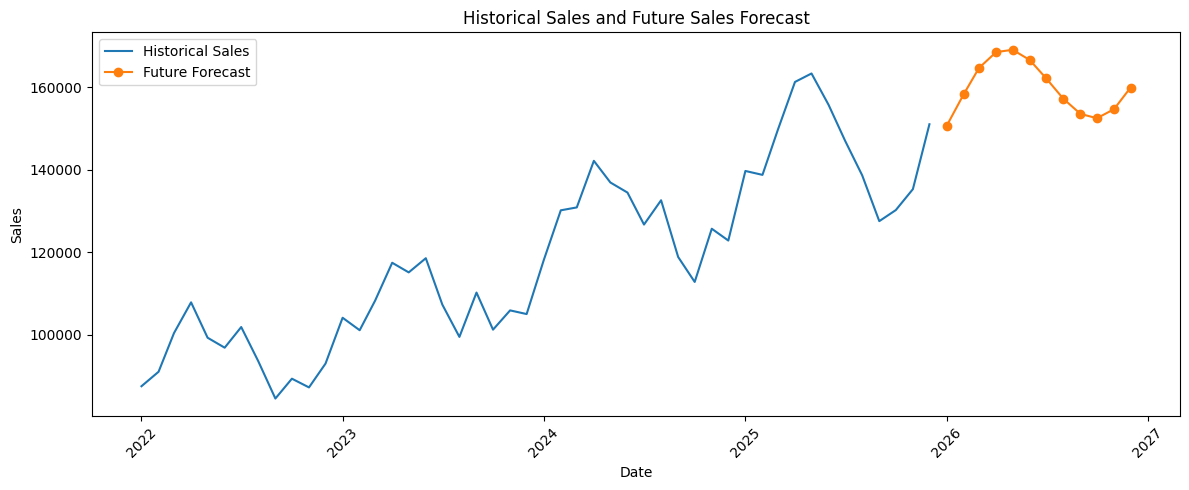

In [40]:
plt.figure(figsize=(12, 5))

plt.plot(
    model_data["Date"],
    model_data["Sales"],
    label="Historical Sales"
)

plt.plot(
    future_data["Date"],
    future_data["Predicted_Sales"],
    marker="o",
    label="Future Forecast"
)

plt.title("Historical Sales and Future Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.show()

In [41]:
future_data[["Date", "Predicted_Sales"]].to_csv(
    "predictions.csv",
    index=False
)

print("Future predictions saved successfully!")

Future predictions saved successfully!


In [42]:
comparison = pd.DataFrame({
    "Date": model_data["Date"].iloc[train_size:].values,
    "Actual_Sales": y_test.values,
    "Predicted_Sales": np.round(y_pred, 2)
})

comparison.to_csv(
    "actual_vs_predicted.csv",
    index=False
)

print("Actual vs predicted results saved successfully!")

Actual vs predicted results saved successfully!


## Conclusion

This project used historical monthly sales data to build a predictive analytics model for forecasting future sales.

The data was cleaned and analyzed to identify historical sales trends and monthly patterns. A Linear Regression model with time and seasonal features was developed to predict sales.

The model achieved the following evaluation results:

- MAE: 5658.48
- RMSE: 6592.32
- R² Score: 0.6955

The model was then used to forecast sales for the next 12 months.

This project demonstrates the use of historical data, regression modeling, model evaluation, visualization, and future forecasting for data-driven decision making.